In [2109]:
# Data Requirements: The data provided includes the following columns:

# App: Name of the app
# Category: Category of the app
# Rating: Average user rating of the app
# Reviews: Number of user reviews
# Size: Size of the app
# Installs: Number of installs
# Type: Whether the app is free or paid
# Price: Price of the app
# Content Rating: Age group for which the app is appropriate
# Genres: Genres of the app
# Last Updated: Date when the app was last updated
# Current Ver: Current version of the app
# Android Ver: Minimum Android version required

In [2110]:
# Imports the libraries for cleaning, numerical operations and plotting.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2111]:
# Step 1: Load the dataset
# Read the Google Play Store Apps CSV file using Pandas.


data = pd.read_csv("/kaggle/input/datasets/lava18/google-play-store-apps/googleplaystore.csv")

# Display the first 5 rows to preview the dataset

data.head(5)

# This dataset contains information about App, categories, ratings, reviews, installs, prices, and other app-related features.

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [2112]:
# Step 2: Explore the dataset
# Check the number of rows and columns, column names, and data types.

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [2113]:
# Filters records with missing ratings.

data[data['Rating'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61,7.0M,"100,000+",Free,0,Everyone,Art & Design;Action & Adventure,"March 7, 2018",1.0.0,4.1 and up
113,Wrinkles and rejuvenation,BEAUTY,NaN,182,5.7M,"100,000+",Free,0,Everyone 10+,Beauty,"September 20, 2017",8.0,3.0 and up
123,Manicure - nail design,BEAUTY,NaN,119,3.7M,"50,000+",Free,0,Everyone,Beauty,"July 23, 2018",1.3,4.1 and up
126,Skin Care and Natural Beauty,BEAUTY,NaN,654,7.4M,"100,000+",Free,0,Teen,Beauty,"July 17, 2018",1.15,4.1 and up
129,"Secrets of beauty, youth and health",BEAUTY,NaN,77,2.9M,"10,000+",Free,0,Mature 17+,Beauty,"August 8, 2017",2.0,2.3 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10824,Cardio-FR,MEDICAL,NaN,67,82M,"10,000+",Free,0,Everyone,Medical,"July 31, 2018",2.2.2,4.4 and up
10825,Naruto & Boruto FR,SOCIAL,NaN,7,7.7M,100+,Free,0,Teen,Social,"February 2, 2018",1.0,4.0 and up
10831,payermonstationnement.fr,MAPS_AND_NAVIGATION,NaN,38,9.8M,"5,000+",Free,0,Everyone,Maps & Navigation,"June 13, 2018",2.0.148.0,4.0 and up
10835,FR Forms,BUSINESS,NaN,0,9.6M,10+,Free,0,Everyone,Business,"September 29, 2016",1.1.5,4.0 and up


In [2114]:
# Check missing ratings
missing_count = data['Rating'].isna().sum()
missing_percentage = data['Rating'].isna().mean() * 100

print(f"Missing Ratings: {missing_count}")
print(f"Missing Percentage: {missing_percentage:.2f}%")

Missing Ratings: 1474
Missing Percentage: 13.60%


In [2115]:
# Fill missing ratings with the overall mean.

data['Rating'] = data['Rating'].fillna(data['Rating'].mean())

In [2116]:
# Counts any missing ratings after imputation.

print(data['Rating'].isna().sum())

0


In [2117]:
# Finds rows with an empty free/paid app type.

data[data["Type"].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,4.193338,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [2118]:
# Check missing values before filling
missing_count = data['Type'].isnull().sum()
missing_percentage = (missing_count / len(data)) * 100

print("Missing Values:", missing_count)
print(f"Missing Percentage: {missing_percentage:.3f}%")

Missing Values: 1
Missing Percentage: 0.009%


In [2119]:
# Fill missing Type values with the most frequent label.

data['Type'] = data['Type'].fillna(data['Type'].mode()[0])

In [2120]:
# Replaces the invalid literal Type value 0 with the mode type.

data['Type'] = data['Type'].replace('0', data['Type'].mode()[0])

In [2121]:
# Lists the remaining Type values.

data['Type'].unique()

array(['Free', 'Paid'], dtype=object)

In [2122]:
# Locates rows without a content-rating label.

data[data['Content Rating'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,Free,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [2123]:
# Check missing values before filling
missing_count = data['Content Rating'].isnull().sum()
missing_percentage = (missing_count / len(data)) * 100

print("Missing Values:", missing_count)
print(f"Missing Percentage: {missing_percentage:.3f}%")

Missing Values: 1
Missing Percentage: 0.009%


In [2124]:
# Replaces missing content ratings with the most common category.

data["Content Rating"] = data['Content Rating'].fillna(data['Content Rating'].mode()[0])

In [2125]:
# Identifies rows missing current version information.

data[data['Current Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.200000,55,2.7M,"5,000+",Free,0,Everyone,Art & Design,"June 6, 2018",NaN,4.2 and up
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.100000,20145,11k,"1,000,000+",Free,0,Everyone,Libraries & Demo,"February 12, 2013",NaN,1.5 and up
6322,Virtual DJ Sound Mixer,TOOLS,4.200000,4010,8.7M,"500,000+",Free,0,Everyone,Tools,"May 10, 2017",NaN,4.0 and up
6803,BT Master,FAMILY,4.193338,0,222k,100+,Free,0,Everyone,Education,"November 6, 2016",NaN,1.6 and up
7333,Dots puzzle,FAMILY,4.000000,179,14M,"50,000+",Paid,$0.99,Everyone,Puzzle,"April 18, 2018",NaN,4.0 and up
7407,Calculate My IQ,FAMILY,4.193338,44,7.2M,"10,000+",Free,0,Everyone,Entertainment,"April 3, 2017",NaN,2.3 and up
7730,UFO-CQ,TOOLS,4.193338,1,237k,10+,Paid,$0.99,Everyone,Tools,"July 4, 2016",NaN,2.0 and up
10342,La Fe de Jesus,BOOKS_AND_REFERENCE,4.193338,8,658k,"1,000+",Free,0,Everyone,Books & Reference,"January 31, 2017",NaN,3.0 and up


In [2126]:
# Check missing values before filling
missing_count = data['Current Ver'].isnull().sum()
missing_percentage = (missing_count / len(data)) * 100

print("Missing Values:", missing_count)
print(f"Missing Percentage: {missing_percentage:.3f}%")

Missing Values: 8
Missing Percentage: 0.074%


In [2127]:
# Fill empty app-version values with Unknown.


data['Current Ver'] = data['Current Ver'].fillna('Unknown')

In [2128]:
# Inspects rows missing Android version requirements.

data[data['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11M,"1,000+",Paid,$1.49,Everyone,Personalization,"July 20, 2018",4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2.1M,"10,000+",Free,0,Everyone,Personalization,"March 27, 2018",1.1,NaN
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,Free,Everyone,Everyone,"February 11, 2018",1.0.19,4.0 and up,NaN


In [2129]:
# Check missing values before filling
missing_count = data['Android Ver'].isnull().sum()
missing_percentage = (missing_count / len(data)) * 100

print("Missing Values:", missing_count)
print(f"Missing Percentage: {missing_percentage:.3f}%")

Missing Values: 3
Missing Percentage: 0.028%


In [2130]:
# Fill missing Android version labels with Unknown.

data['Android Ver'] = data['Android Ver'].fillna('Unknown')

In [2131]:
data.info()

# Clean the dataset by handling missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          10841 non-null  float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10841 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10841 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10841 non-null  object 
 12  Android Ver     10841 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [2132]:
# Displays a five-row data preview.

data.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [2133]:
# Lists distinct installation-count strings.

data['Installs'].unique()

array(['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+',
       '50,000+', '1,000,000+', '10,000,000+', '5,000+', '100,000,000+',
       '1,000,000,000+', '1,000+', '500,000,000+', '50+', '100+', '500+',
       '10+', '1+', '5+', '0+', '0', 'Free'], dtype=object)

In [2134]:
# Removes punctuation and substitutes zero for the invalid Free installs value.

data['Installs'] = data['Installs'].str.replace('+','').str.replace('Free','0').str.replace(',','')

In [2135]:
# Casts normalized install counts to integers.

data['Installs'] = data['Installs'].astype(int)

In [2136]:
# Inspects the original app-price values.

data['Price'].unique()

array(['0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99', '$7.99', '$5.99',
       '$3.49', '$1.99', '$9.99', '$7.49', '$0.99', '$9.00', '$5.49',
       '$10.00', '$24.99', '$11.99', '$79.99', '$16.99', '$14.99',
       '$1.00', '$29.99', '$12.99', '$2.49', '$10.99', '$1.50', '$19.99',
       '$15.99', '$33.99', '$74.99', '$39.99', '$3.95', '$4.49', '$1.70',
       '$8.99', '$2.00', '$3.88', '$25.99', '$399.99', '$17.99',
       '$400.00', '$3.02', '$1.76', '$4.84', '$4.77', '$1.61', '$2.50',
       '$1.59', '$6.49', '$1.29', '$5.00', '$13.99', '$299.99', '$379.99',
       '$37.99', '$18.99', '$389.99', '$19.90', '$8.49', '$1.75',
       '$14.00', '$4.85', '$46.99', '$109.99', '$154.99', '$3.08',
       '$2.59', '$4.80', '$1.96', '$19.40', '$3.90', '$4.59', '$15.46',
       '$3.04', '$4.29', '$2.60', '$3.28', '$4.60', '$28.99', '$2.95',
       '$2.90', '$1.97', '$200.00', '$89.99', '$2.56', '$30.99', '$3.61',
       '$394.99', '$1.26', 'Everyone', '$1.20', '$1.04'], dtype=object)

In [2137]:
# Strips currency symbols and replaces the malformed Everyone price with zero.

data['Price'] = data['Price'].str.replace('Everyone','0').str.replace('$','').str.strip()

In [2138]:
# Converts cleaned prices to floating-point numbers.

data['Price'] = data['Price'].astype(float)

In [2139]:
# Verifies the converted price values.

data['Price'].unique()

array([  0.  ,   4.99,   3.99,   6.99,   1.49,   2.99,   7.99,   5.99,
         3.49,   1.99,   9.99,   7.49,   0.99,   9.  ,   5.49,  10.  ,
        24.99,  11.99,  79.99,  16.99,  14.99,   1.  ,  29.99,  12.99,
         2.49,  10.99,   1.5 ,  19.99,  15.99,  33.99,  74.99,  39.99,
         3.95,   4.49,   1.7 ,   8.99,   2.  ,   3.88,  25.99, 399.99,
        17.99, 400.  ,   3.02,   1.76,   4.84,   4.77,   1.61,   2.5 ,
         1.59,   6.49,   1.29,   5.  ,  13.99, 299.99, 379.99,  37.99,
        18.99, 389.99,  19.9 ,   8.49,   1.75,  14.  ,   4.85,  46.99,
       109.99, 154.99,   3.08,   2.59,   4.8 ,   1.96,  19.4 ,   3.9 ,
         4.59,  15.46,   3.04,   4.29,   2.6 ,   3.28,   4.6 ,  28.99,
         2.95,   2.9 ,   1.97, 200.  ,  89.99,   2.56,  30.99,   3.61,
       394.99,   1.26,   1.2 ,   1.04])

In [2140]:
data.info()

# Converted Installs and Price columns from string/object to numeric data types for analysis.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          10841 non-null  float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  int64  
 6   Type            10841 non-null  object 
 7   Price           10841 non-null  float64
 8   Content Rating  10841 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10841 non-null  object 
 12  Android Ver     10841 non-null  object 
dtypes: float64(2), int64(1), object(10)
memory usage: 1.1+ MB


In [2141]:
# Identifies records duplicated across every original field.

data[data.duplicated(subset = ['App','Category','Rating','Reviews','Size','Installs','Type','Price','Content Rating','Genres','Last Updated','Current Ver','Android Ver'])]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,5000000,Free,0.0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,10000000,Free,0.0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,5000000,Free,0.0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,10000000,Free,0.0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,1000000,Free,0.0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8643,Wunderlist: To-Do List & Tasks,PRODUCTIVITY,4.6,404610,Varies with device,10000000,Free,0.0,Everyone,Productivity,"April 6, 2018",Varies with device,Varies with device
8654,"TickTick: To Do List with Reminder, Day Planner",PRODUCTIVITY,4.6,25370,Varies with device,1000000,Free,0.0,Everyone,Productivity,"August 6, 2018",Varies with device,Varies with device
8658,ColorNote Notepad Notes,PRODUCTIVITY,4.6,2401017,Varies with device,100000000,Free,0.0,Everyone,Productivity,"June 27, 2018",Varies with device,Varies with device
10049,Airway Ex - Intubate. Anesthetize. Train.,MEDICAL,4.3,123,86M,10000,Free,0.0,Everyone,Medical,"June 1, 2018",0.6.88,5.0 and up


In [2142]:
# Check duplicate records before removing
duplicate_count = data.duplicated().sum()
duplicate_percentage = (duplicate_count / len(data)) * 100

print("Duplicate Records:", duplicate_count)
print(f"Duplicate Percentage: {duplicate_percentage:.2f}%")

Duplicate Records: 483
Duplicate Percentage: 4.46%


In [2143]:
# Store row count before removing duplicates
rows_before = len(data)

# Remove duplicates
data = data.drop_duplicates(subset = ['App','Category','Rating','Reviews','Size','Installs','Type','Price','Content Rating','Genres','Last Updated','Current Ver','Android Ver'])

# Calculate removed records
rows_removed = rows_before - len(data)

print("Rows Before:", rows_before)
print("Rows After:", len(data))
print("Rows Removed:", rows_removed)

Rows Before: 10841
Rows After: 10358
Rows Removed: 483


In [2144]:
# Checks dataset shape after duplicate removal.

data.info()

# Identified and removed 483 duplicate rows to maintain data quality and consistency.

<class 'pandas.core.frame.DataFrame'>
Index: 10358 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10358 non-null  object 
 1   Category        10358 non-null  object 
 2   Rating          10358 non-null  float64
 3   Reviews         10358 non-null  object 
 4   Size            10358 non-null  object 
 5   Installs        10358 non-null  int64  
 6   Type            10358 non-null  object 
 7   Price           10358 non-null  float64
 8   Content Rating  10358 non-null  object 
 9   Genres          10358 non-null  object 
 10  Last Updated    10358 non-null  object 
 11  Current Ver     10358 non-null  object 
 12  Android Ver     10358 non-null  object 
dtypes: float64(2), int64(1), object(10)
memory usage: 1.1+ MB


In [2145]:
# Displays the current category labels.

data['Category'].unique()

array(['ART_AND_DESIGN', 'AUTO_AND_VEHICLES', 'BEAUTY',
       'BOOKS_AND_REFERENCE', 'BUSINESS', 'COMICS', 'COMMUNICATION',
       'DATING', 'EDUCATION', 'ENTERTAINMENT', 'EVENTS', 'FINANCE',
       'FOOD_AND_DRINK', 'HEALTH_AND_FITNESS', 'HOUSE_AND_HOME',
       'LIBRARIES_AND_DEMO', 'LIFESTYLE', 'GAME', 'FAMILY', 'MEDICAL',
       'SOCIAL', 'SHOPPING', 'PHOTOGRAPHY', 'SPORTS', 'TRAVEL_AND_LOCAL',
       'TOOLS', 'PERSONALIZATION', 'PRODUCTIVITY', 'PARENTING', 'WEATHER',
       'VIDEO_PLAYERS', 'NEWS_AND_MAGAZINES', 'MAPS_AND_NAVIGATION',
       '1.9'], dtype=object)

In [2146]:
# Converts Category into a categorical datatype.

data['Category']= data['Category'].astype('category')

In [2147]:
# Checks genre names and counts distinct genre values.

data['Genres'].unique()
data['Genres'].nunique()

120

In [2148]:
# Converts Genres to a categorical datatype.

data['Genres'] = data['Genres'].astype('category')

In [2149]:
# Inspects dtypes after category and genre conversions.

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10358 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   App             10358 non-null  object  
 1   Category        10358 non-null  category
 2   Rating          10358 non-null  float64 
 3   Reviews         10358 non-null  object  
 4   Size            10358 non-null  object  
 5   Installs        10358 non-null  int64   
 6   Type            10358 non-null  object  
 7   Price           10358 non-null  float64 
 8   Content Rating  10358 non-null  object  
 9   Genres          10358 non-null  category
 10  Last Updated    10358 non-null  object  
 11  Current Ver     10358 non-null  object  
 12  Android Ver     10358 non-null  object  
dtypes: category(2), float64(2), int64(1), object(8)
memory usage: 997.6+ KB


In [2150]:
# Parses the Last Updated column as dates and coerces invalid strings to NaT.

data['Last Updated'] = pd.to_datetime(data['Last Updated'],format = 'mixed', errors = 'coerce')


# Data cleaning and preprocessing completed successfully.
# Handled missing values, converted data types, removed duplicates and formatted dates for further analysis.# 

In [2151]:
data.info()

# Data cleaning and preprocessing completed successfully.
# Handled missing values, converted data types, removed duplicates and formatted dates for further analysis.

<class 'pandas.core.frame.DataFrame'>
Index: 10358 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10358 non-null  object        
 1   Category        10358 non-null  category      
 2   Rating          10358 non-null  float64       
 3   Reviews         10358 non-null  object        
 4   Size            10358 non-null  object        
 5   Installs        10358 non-null  int64         
 6   Type            10358 non-null  object        
 7   Price           10358 non-null  float64       
 8   Content Rating  10358 non-null  object        
 9   Genres          10358 non-null  category      
 10  Last Updated    10357 non-null  datetime64[ns]
 11  Current Ver     10358 non-null  object        
 12  Android Ver     10358 non-null  object        
dtypes: category(2), datetime64[ns](1), float64(2), int64(1), object(7)
memory usage: 997.6+ KB


# Basic-Level Questions:

In [2152]:
# 1. What is the average rating of apps in the dataset?

data['Rating'].mean().round(2)

# The average rating of apps in the dataset is 4.19 out of 5.

np.float64(4.19)

In [2153]:
# 2. How many unique categories of apps are there?

data['Category'].nunique()

# There are 34 unique app categories in the dataset.

34

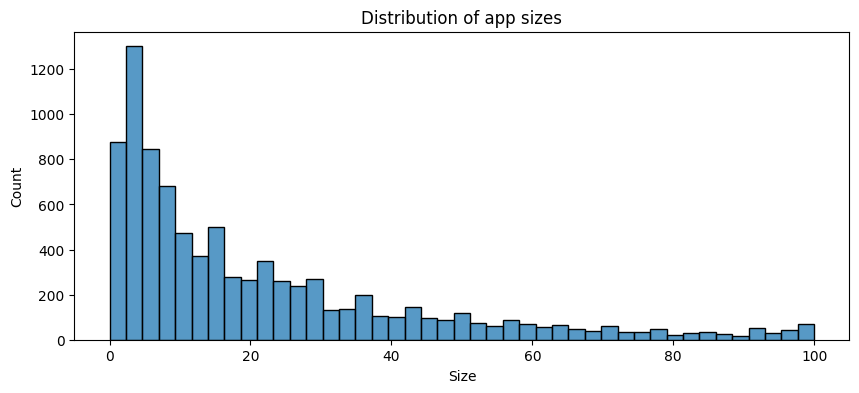

In [2154]:
# 3. What is the distribution of app sizes?

data['Size'] = data['Size'].replace('Varies with device',np.nan)


data['Size'] = data['Size'].apply(
    lambda x: float(x[:-1]) / 1024 if isinstance(x, str) and x.endswith('k')
    else float(x[:-1]) if isinstance(x, str) and x.endswith('M')
    else np.nan)

plt.figure(figsize=(10,4))

sns.histplot(data = data,x='Size')

plt.title('Distribution of app sizes')
plt.show()


# The histogram shows the distribution of app sizes in the dataset.

# Most apps have smaller sizes, while fewer apps have larger sizes.



In [2155]:
# 4. How many free vs paid apps are there?

data['Type'].value_counts()

# There are 9,593 free apps and 765 paid apps.

Type
Free    9593
Paid     765
Name: count, dtype: int64

In [2156]:
# 5. What is the most common content rating for apps?

data['Content Rating'].mode()

# Everyone is the most common content rating among apps.

0    Everyone
Name: Content Rating, dtype: object

In [2157]:
# 6. What are the top 5 most installed apps?

data[['App','Installs']].sort_values(by = 'Installs',ascending=False).head(5)


# The top 5 most installed apps are Google, Google+, Instagram, Google News, and Google Photos. All five apps have 1 billion installs,
# showing their popularity among Android users.



,App,Installs
3234,Google,1000000000
2554,Google+,1000000000
2545,Instagram,1000000000
3736,Google News,1000000000
5395,Google Photos,1000000000


In [2158]:
# 7. How many apps have a rating of 4.0 and above?

m1 = data['Rating'] >= 4.0
data[m1]['Rating'].count()

# There are 8413 apps with a rating of 4.0 and above.

np.int64(8413)

In [2159]:
# 8. What is the average number of reviews for free vs paid apps?

data['Reviews'] = pd.to_numeric(data['Reviews'], errors = 'coerce')

data.groupby('Type')['Reviews'].mean().round(2)


# Converts review counts to numeric and compares mean reviews by app Type.
# Free apps have an average of 437328.00 reviews.
# While paid apps have an average of 11900.55 reviews.
# This indicates that free apps receive significantly more reviews than paid apps.

Type
Free    437328.00
Paid     11900.55
Name: Reviews, dtype: float64

In [2160]:
# 9. What is the average app size for each category?


# Remove rows with incorrect Category value

data = data[data['Category'].astype(str) != '1.9'].copy()

# Remove unused categories

data['Category'] = data['Category'].cat.remove_unused_categories()

# Average app size by category in descending order

data.groupby('Category', observed=False)['Size'].mean().sort_values(ascending=False).round(2)


# The GAME category has the highest average app size (44.13 MB),
# while TOOLS has the lowest average app size (8.77 MB).

Category
GAME                   44.13
FAMILY                 27.93
TRAVEL_AND_LOCAL       24.52
SPORTS                 24.18
ENTERTAINMENT          22.64
PARENTING              22.51
FOOD_AND_DRINK         22.06
HEALTH_AND_FITNESS     21.64
EDUCATION              20.08
AUTO_AND_VEHICLES      20.04
MEDICAL                19.38
FINANCE                17.94
SOCIAL                 16.88
PHOTOGRAPHY            16.83
MAPS_AND_NAVIGATION    16.61
VIDEO_PLAYERS          16.08
HOUSE_AND_HOME         15.97
SHOPPING               15.90
DATING                 15.83
LIFESTYLE              14.86
EVENTS                 13.96
BUSINESS               13.91
BEAUTY                 13.80
COMICS                 13.48
BOOKS_AND_REFERENCE    13.19
WEATHER                13.12
PRODUCTIVITY           12.87
NEWS_AND_MAGAZINES     12.65
ART_AND_DESIGN         12.37
COMMUNICATION          11.66
PERSONALIZATION        11.29
LIBRARIES_AND_DEMO     11.08
TOOLS                   8.77
Name: Size, dtype: float64

In [2161]:
# 10. How many apps were last updated in 2018?

data['Last Updated'] = pd.to_datetime(data['Last Updated'])

(data['Last Updated'].dt.year == 2018).sum()

# A total of 6934 apps were last updated in 2018.

np.int64(6934)

# Medium-Level Questions:

In [2162]:
# 1. What is the correlation between the number of installs and the app rating?

data['Installs'].corr(data['Rating'])

# The correlation between Installs and Rating is 0.050473.

# Insights : The correlation between installs and app ratings is approximately 0.05, indicating a very weak positive linear relationship.


np.float64(0.05047339708784072)

In [2163]:
# 2. Which app categories have the highest average rating?

data.groupby('Category',observed=True)["Rating"].mean().sort_values(ascending=False)

# The EDUCATION category has the highest average rating (4.37),followed by EVENTS (4.36) and ART_AND_DESIGN (4.35).
# The DATING category has the lowest average rating (4.01).
# Overall, EDUCATION and EVENTS are the top-rated app categories.

Category
EDUCATION              4.374564
EVENTS                 4.363647
ART_AND_DESIGN         4.350462
BOOKS_AND_REFERENCE    4.311943
PERSONALIZATION        4.305620
PARENTING              4.282223
GAME                   4.277598
BEAUTY                 4.260882
HEALTH_AND_FITNESS     4.251656
SOCIAL                 4.247001
SHOPPING               4.245774
WEATHER                4.239675
SPORTS                 4.219279
PRODUCTIVITY           4.200279
FAMILY                 4.191406
AUTO_AND_VEHICLES      4.190824
MEDICAL                4.185279
PHOTOGRAPHY            4.183479
LIBRARIES_AND_DEMO     4.181962
HOUSE_AND_HOME         4.169001
FOOD_AND_DRINK         4.168388
COMMUNICATION          4.158216
COMICS                 4.156445
NEWS_AND_MAGAZINES     4.140784
ENTERTAINMENT          4.136036
BUSINESS               4.135958
FINANCE                4.135315
LIFESTYLE              4.113799
TRAVEL_AND_LOCAL       4.107539
VIDEO_PLAYERS          4.074858
TOOLS                  4.066280

In [2164]:
# 3. How does the price of an app affect its average rating?

data[data['Type'] == 'Paid'].groupby('Price')['Rating'].mean().round(2)


# The average ratings of paid apps vary across different price points.
# Higher-priced apps do not always have higher ratings. Therefore, there is no clear evidence that increasing the price leads to higher app ratings.

Price
0.99      4.27
1.00      4.36
1.04      4.19
1.20      4.20
1.26      4.19
          ... 
379.99    2.90
389.99    3.60
394.99    4.19
399.99    4.02
400.00    3.60
Name: Rating, Length: 91, dtype: float64

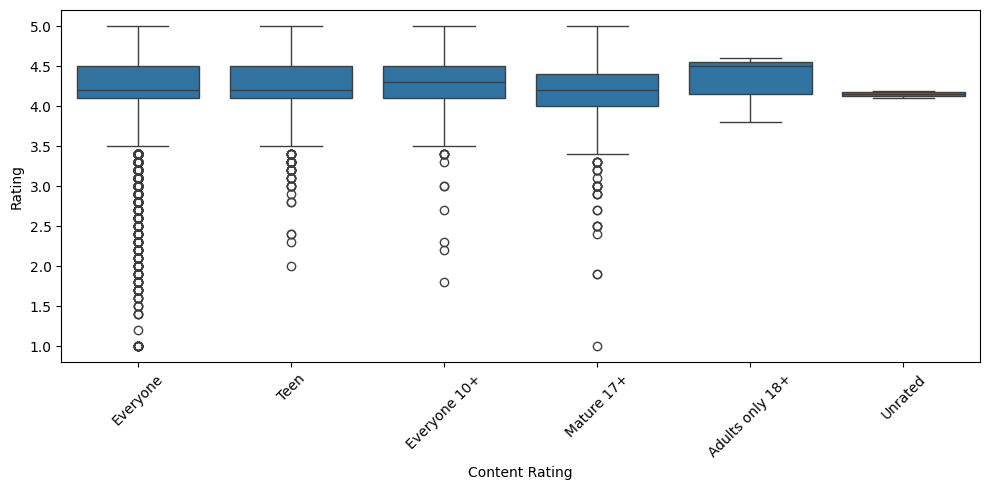

In [2165]:
# 4. What is the distribution of app ratings across different content ratings?

plt.figure(figsize=(10,5))

sns.boxplot(data= data, x = 'Content Rating', y = 'Rating')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [2166]:
# 5. Which genres have the most apps with over 1 million installs?

data[data['Installs'] > 1000000].groupby('Genres',observed=True).size().sort_values(ascending=False)


# Tools has the highest number of apps with over 1 million installs (187),followed by Action (182) and Photography (161).
# These genres show strong popularity among high-install apps.
# This insight can help guide genre-specific app development and marketing.

Genres
Tools                        187
Action                       182
Photography                  161
Communication                146
Productivity                 124
                            ... 
Parenting                      1
Role Playing;Brain Games       1
Parenting;Music & Video        1
Sports;Action & Adventure      1
Tools;Education                1
Length: 88, dtype: int64

In [2167]:
# 6. How frequently do apps get updated? Calculate the average time between updates.

data = data.sort_values(['App','Last Updated'])

data.groupby('App')['Last Updated'].diff().mean()


# Sorts by app and last-update date, then averages within-app date differences.
# The average time between consecutive update dates for apps with multiple records is approximately 7 days and 21 hours.

Timedelta('7 days 21:06:42.292263610')

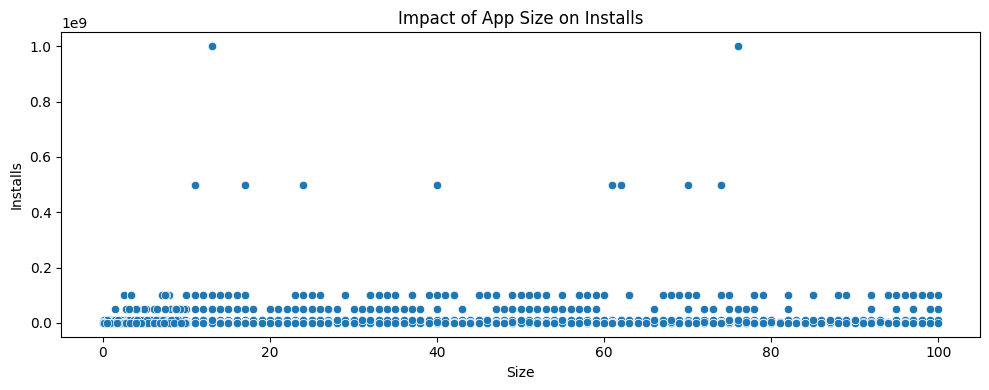

In [2168]:
# 7. What is the impact of app size on the number of installs?

plt.figure(figsize=(10,4))

sns.scatterplot(data=data, x = 'Size', y = 'Installs')

plt.xlabel('Size')
plt.ylabel('Installs')
plt.title('Impact of App Size on Installs')
plt.tight_layout()
plt.show()

# The scatter plot shows no clear relationship between app size and installs.
# Both small and large apps have varying numbers of installs.
# This suggests that app size alone does not determine the number of installs.

In [2169]:
# 8. Which apps have the highest number of reviews, and what are their ratings?

data.sort_values('Reviews',ascending=False)[['App','Reviews','Rating']].head()

,App,Reviews,Rating
2544,Facebook,78158306.0,4.1
3943,Facebook,78128208.0,4.1
336,WhatsApp Messenger,69119316.0,4.4
3904,WhatsApp Messenger,69109672.0,4.4
2604,Instagram,66577446.0,4.5


In [2170]:
# 9. How does the content rating distribution differ between free and paid apps?

pd.crosstab(data['Content Rating'], data['Type']).sort_values(by=['Free', 'Paid'],ascending=False)

# The Everyone category dominates both free and paid apps, followed by Teen. 
# Free apps have higher counts across all content rating categories, 
# while Adults only 18+ and Unrated apps are extremely rare.

Type,Free,Paid
Content Rating,,
Everyone,7720,662
Teen,1094,52
Mature 17+,428,19
Everyone 10+,345,32
Adults only 18+,3,0
Unrated,2,0


In [2171]:
# 10. What are the top 5 categories with the most installs?


data.groupby('Category',observed=False)['Installs'].sum().sort_values(ascending=False).head(5)


# GAME category has the highest number of installs, followed by COMMUNICATION, SOCIAL, PRODUCTIVITY, and TOOLS also have a high number of installs.
# The top 5 categories account for a significant share of total installs.

Category
GAME             31544024415
COMMUNICATION    24152276251
SOCIAL           12513867902
PRODUCTIVITY     12463091369
TOOLS            11452771915
Name: Installs, dtype: int64

# Advanced-Level Questions:

In [2172]:
# 1. What are the top 10 apps with the highest ratings, and how do their number of reviews and installs compare?

data[['App','Rating','Reviews','Installs']].sort_values(by = ['Rating'],ascending=False).head(10)

# All top 10 apps have the highest rating of 5.0.
# The number of reviews and installs varies significantly across these apps.
# Some apps have high ratings despite having very few reviews and installs.

# For business decisions, highly rated apps with more reviews and installs may provide more reliable benchmarks for app development and marketing.

,App,Rating,Reviews,Installs
5763,Tozer Devotional -Series 1,5.0,5.0,1000
7754,CricQuick,5.0,17.0,50
8018,30WPM Amateur ham radio Koch CW Morse code tra...,5.0,1.0,10
9301,EF Academy,5.0,4.0,50
2427,Sway Medical,5.0,3.0,100
7534,CL Strength,5.0,3.0,50
7506,CL REPL,5.0,47.0,1000
7623,CN Resident,5.0,1.0,100
1038,Mindvalley U Tallinn 2018,5.0,1.0,100
9282,EF Events,5.0,7.0,100


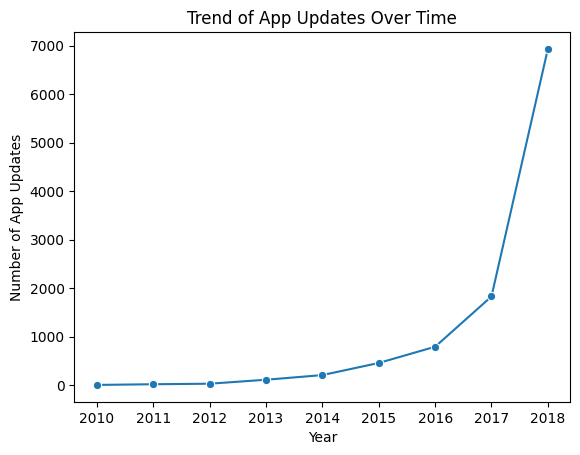

In [2173]:
# 2. Analyze the trend of app updates over time. Are there any noticeable patterns or seasonal trends?

data['Year'] = data['Last Updated'].dt.year

updates = data.groupby('Year').size()

sns.lineplot(x=updates.index, y=updates.values, marker='o')

plt.xlabel('Year')
plt.ylabel('Number of App Updates')
plt.title('Trend of App Updates Over Time')
plt.show()

In [2174]:
# 3. How does the average rating of apps change with the number of installs? Create a binned analysis.

bins = [0,1000, 10000, 100000, 1000000, 10000000, float('inf')]

data['Installs_bins'] = pd.cut(data['Installs'],bins = bins)

data.groupby('Installs_bins', observed = True)['Rating'].mean().sort_values(ascending=False)



Installs_bins
(10000000.0, inf]          4.372170
(1000000.0, 10000000.0]    4.285675
(100000.0, 1000000.0]      4.207022
(0.0, 1000.0]              4.195929
(10000.0, 100000.0]        4.096502
(1000.0, 10000.0]          4.040493
Name: Rating, dtype: float64

In [2175]:
# 4. Perform sentiment analysis on app reviews (if review text is available) to determine the common themes in high and low-rated apps.


# Review is not available in Text format

In [2176]:
# 5. What is the relationship between app genre and user ratings? Are certain genres consistently rated higher or lower?

data.groupby('Genres', observed = True)['Rating'].agg(['mean','median']).sort_values(by = 'mean',ascending=False)

,mean,median
Genres,,
Board;Pretend Play,4.800000,4.8
Comics;Creativity,4.800000,4.8
Health & Fitness;Education,4.700000,4.7
Puzzle;Education,4.600000,4.6
Strategy;Action & Adventure,4.600000,4.6
...,...,...
Educational;Creativity,3.960000,4.2
Educational,3.915316,4.0
Art & Design;Pretend Play,3.900000,3.9


# Final App Insights and Key Findings


This conclusion covers all 25 analysis questions in the notebook: 10 Basic, 10 Medium and 5 Advanced. 
Dataset preparation and quality
- The raw data has 10,841 rows and 13 columns. Removing 483 exact duplicates yields 10,358 rows; excluding one invalid-category row later leaves 10,357 rows. The final dataset has 15 columns, including derived fields.
- Missing Rating values were filled with the overall mean, and some categorical missing/invalid values were replaced. These replacements are assumptions, not observed app properties. The invalid category 1.9 originates from a malformed record.
- Installs values such as 1,000,000+ are bracket thresholds, not precise install counts. Size calculations exclude Varies with device. The Last Updated column records only the most recent update date shown in the snapshot, not each app’s update history.
Basic-Level Questions (1–10)
1. What is the average rating of apps?
The mean rating is 4.19/5. The result includes ratings filled with the mean, so it slightly overstates the amount of directly observed feedback.

2. How many unique categories are there?
The notebook reports 34 before the malformed 1.9 category is removed. That includes one invalid category, so 33 valid category labels remain after its removal.

3. What is the distribution of app sizes?
The histogram indicates many apps are relatively small, with fewer large-size apps and a right-skewed distribution. Sizes labelled Varies with device are excluded from this numeric analysis; the chart alone does not establish an exact median or percentage.

4. How many free versus paid apps are there?
There are 9,593 Free and 765 Paid listings at this stage (about 92.6% Free). Free apps overwhelmingly dominate the recorded market. The malformed row is removed only in a later cell.

5. What is the most common content rating?
Everyone is the modal content rating. The dataset is largely composed of apps intended for a general audience, although a missing value was imputed during cleaning.

6. What are the top five most installed apps?
The displayed five are Google, Google+, Instagram, Google News and Google Photos. Each shows 1,000,000,000 in the normalized Installs column. These are tied lower-bound install brackets, so the output cannot establish a true top-five ranking or exact download totals.

7. How many apps have a rating of 4.0 and above?
8,413 listings meet the Rating >= 4.0 condition at this point in the analysis. Since missing ratings were imputed with a mean above 4, some included listings have no original observed rating.

8. What is the average number of reviews for free vs paid apps?
Free apps have around 437,328 reviews on average, versus 11,901 for paid apps. This is a large descriptive difference, likely sensitive to extreme high-review apps; it does not demonstrate that free pricing causes higher engagement.

9. What is the average app size for each category?
From the saved output, GAME (~44.13 MB) has the highest mean recorded size; FAMILY (27.93 MB) and TRAVEL_AND_LOCAL (24.52 MB) also appear near the top. The notebook calculates all category means, but these figures exclude variable-size records.

10. How many apps were last updated in 2018?
6,934 listings have a Last Updated year of 2018. This counts apps whose last recorded update was in 2018, not the number of updates made that year.
Medium-Level Questions (1–10)
1. What is the correlation between installs and app rating?
Pearson correlation is ~0.0505, a negligible positive linear relationship. High install thresholds do not reliably imply high ratings in this dataset.

2. Which categories have the highest average rating?
The top three reported categories are EDUCATION (4.37), EVENTS (4.36) and ART_AND_DESIGN (4.35). Category sizes and imputed ratings should be examined before declaring one category consistently better.

3. How does price affect average rating?
Ratings vary across exact paid-app price points. For example, the output reports $0.99: 4.27 and $1.00: 4.36, while several high-price levels are lower. There is no simple consistent price–rating trend demonstrated; counts per price level would be needed to judge reliability.

4. How are ratings distributed across content ratings?
The boxplot compares distributions across audience categories, but does not provide a precise numerical ranking in the saved output. Overlap and group sizes matter. Do not claim one content-rating group is definitively highest without extracting group statistics.

5. Which genres have the most apps with over one million installs?
Among records satisfying Installs > 1,000,000, Tools (187), Action (182) and Photography (161) have the most listings in the output, followed by Communication (146) and Productivity (124). The strict > filter excludes the 1,000,000+ bracket itself.

6. How frequently are apps updated?
The code prints roughly 7 days 21 hours, but this is not a valid average update frequency. It differences Last Updated timestamps for rows with the same app name; the dataset does not contain historical sequences of updates per app. The frequency question cannot be answered reliably here.

7. What is the impact of app size on installs?
The scatterplot does not indicate a clear simple linear relationship. Because installs are thresholds and the graphic has no fitted statistic, the notebook does not quantify whether app size materially affects installs.

8. Which apps have the highest reviews, and what are their ratings?
This question is not answered correctly by the existing code. sort_values('Reviews').head()['Rating'] selects the lowest, not highest, reviews and omits app names and review totals. Correct it with data.nlargest(5, 'Reviews')[['App', 'Reviews', 'Rating']], then interpret the new result. No top-reviewed app names should be inferred from the saved output.

9. How do content ratings differ for free and paid apps?
Everyone dominates both groups (7,720 Free; 662 Paid); Teen follows (1,094 Free; 52 Paid). Counts are much larger for free apps partly because there are many more free listings. Compare within-type percentages for a fair distribution comparison.

10. Which five categories have the most installs?
By summed Installs threshold values, the leading categories are GAME (31.54B), COMMUNICATION (24.15B), SOCIAL (12.51B), PRODUCTIVITY (12.46B) and TOOLS (11.45B). These are not verified aggregate download totals.
Advanced-Level Questions (1–5)
1. Which ten apps have the highest rating, and how do reviews and installs compare?
The displayed top ten share 5.0/5 ratings, but at least some have extremely few reviews (for example, a displayed app has 1 review, and another 5). A perfect rating with minimal feedback is not equivalent to a highly validated rating. The sorting does not provide a robust quality ranking without review-count criteria.

2. What is the app-update trend over time? Are there seasonal patterns?
The annual chart shows how the latest recorded update year is distributed across app listings, with 2018 prominent (6,934 from the basic analysis). It does not plot every app update or monthly/seasonal activity, so seasonality cannot be established.

3. How does average rating change across install-count bins?
The output shows 4.04 for the (1,000, 10,000] bin, 4.10 for (10,000, 100,000], 4.21 for (100,000, 1,000,000], 4.29 for (1,000,000, 10,000,000] and 4.37 for >10,000,000. The (0, 1,000] bin is 4.20. This is a descriptive bin pattern, not a monotonic trend across every bin or evidence that installs increase ratings.

4. What does sentiment analysis reveal about reviews?
Not answerable using this dataset. The Reviews column contains counts rather than written review text. Identifying positive or negative themes requires an additional review-text dataset.

5. Which genres are consistently higher or lower rated?
The notebook ranks genre means and medians. Board;Pretend Play and Comics;Creativity both show ~4.8 mean ratings near the top, while Health & Fitness;Education appears around 4.7. Without per-genre sample sizes and rating uncertainty, isolated niche genres should not be called consistently better. The median table adds a more outlier-resistant view but does not solve small-sample limitations.
Overall conclusion
This historical dataset is dominated by free app listings and high installation thresholds in GAME, COMMUNICATION and SOCIAL categories. Average ratings are generally favorable, yet rating and install thresholds have almost no overall linear correlation. Genre, category, price, size and content-rating summaries can describe patterns in this sample; they cannot establish what causes success. Update frequency, review sentiment and top-reviewed app rankings remain unresolved or incorrectly computed in the current notebook, and should be fixed or supplemented before those claims are used in a report.

# Overall conclusion

**This historical dataset is dominated by free app listings and high installation thresholds in GAME, COMMUNICATION and SOCIAL categories. Average ratings are generally favorable, yet rating and install thresholds have almost no overall linear correlation. Genre, category, price, size and content-rating summaries can describe patterns in this sample; they cannot establish what causes success. Update frequency, review sentiment and top-reviewed app rankings remain unresolved or incorrectly computed in the current notebook, and should be fixed or supplemented before those claims are used in a report.**